## Reproducing Figure 8 with Wu-Yang Method for KS Inversion
Please check the original paper of the Wu-Yang method: [Qin Wu, Weitao Yang, J. Chem. Phys. 118, 2498 (2003)](https://aip.scitation.org/doi/abs/10.1063/1.1535422?casa_token=caPxLNp1Jm8AAAAA:WsOECHVnX79_uiv6Gxx7DcxXcQ2QTl-_wRKNVekhXK9gIvVZ22T2oFk9_hya4Tc8C7iixmki3YceYA).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from pyscf import gto, scf

import n2v

import matplotlib as mpl
mpl.rcParams["font.size"] = 11
mpl.rcParams["font.family"] = "sans-serif"
mpl.rcParams["axes.edgecolor"] = "#eae8e9" 

In [26]:
rs = [0.5+0.025*i for i in range(60)]
vks_list = []
dens_list = []
ener_list = []
fock_list = []
nuc_list = []
tv_list = []
mf_list = []

basis = "6-31G(d)"
pbs = "aug-cc-pVDZ"
# Define Molecule
for r in rs[:]:
    xyz = f"""
                  H {-1.5*r} 0 0;
                  H {-0.5*r} 0 0;
                  H {0.5*r} 0 0;
                  H {1.5*r} 0 0;
                  """
    print(xyz)
    mol = gto.M(atom = xyz,
    basis = basis)

    # Perform Calculation
    mf = mol.KS()
    mf = scf.RHF(mol)
    mf.xc = 'scan'
    mf.kernel()

    from tangelo import SecondQuantizedMolecule
    from tangelo.algorithms.classical import FCISolver
    mf1 = SecondQuantizedMolecule(xyz, 0, 0, basis = basis)
    #mf.mo_coeff = mf1.mo_coeff
    mf1.mo_coeff = mf.mo_coeff
    fci = FCISolver(mf1)
    efci = fci.simulate()
    mf_list.append(mf1.mean_field.e_tot)
    ener_list.append(efci)
    rdm = fci.get_rdm()[0]
    print(np.trace(rdm))
    rdm = mf1.mo_coeff@rdm@mf1.mo_coeff.T
    print(np.trace(rdm))

    # Extract data for n2v. 
    da, db = mf.make_rdm1()/2, mf.make_rdm1()/2
    da, db = rdm/2, rdm/2
    ovlp = mf.get_ovlp()
    from scipy.linalg import sqrtm
    s1h = sqrtm(ovlp)
    sm1h = sqrtm(np.linalg.inv(ovlp))
    print(np.trace(ovlp@da))
    #da, db = rdm/2, rdm/2
    ca, cb = mf.mo_coeff[:,:mol.nelec[0]], mf.mo_coeff[:, :mol.nelec[1]]
    ea, eb = mf.mo_energy, mf.mo_energy

    # Initialize inverter object. 
    inv = n2v.Inverter( engine='pyscf' )
    nuc_list.append(mf1.mean_field.energy_nuc())

    inv.set_system( mol, basis, pbs=pbs )
    inv.Dt = [da, db]
    inv.ct = [ca, cb]
    inv.et = [ea, eb]

    # Inverter with WuYang method, guide potention v0=Fermi-Amaldi
    inv.invert("WuYang", guide_components="fermi_amaldi", reg=1.e-3, gtol=1.e-4)

    # Build Grid
    inv.eng.grid.build_rectangular((81,51,51)) #81,51,51
    x = inv.eng.grid.x
    y = inv.eng.grid.y
    z = inv.eng.grid.z


    fock_list.append(np.trace((inv.Fock)@(da+db)))
    tv_list.append(np.trace(mf.get_hcore()@(da+db)))
    ###### Get Hartree and Fermi-Amadli Potentials:

    vH = inv.eng.grid.hartree(density=inv.Dt[0]+inv.Dt[1], grid='rectangular')
    vFA = (1-1/(inv.nalpha + inv.nbeta)) * vH

    from gbasis.evals.density import (evaluate_density, 
#                                   evaluate_posdef_kinetic_energy_density,
                                  evaluate_density_laplacian,
                                  evaluate_density_gradient,
 #                                 evaluate_general_kinetic_energy_density,
                                )
    from gbasis.evals.eval import evaluate_basis
    from gbasis.evals.eval_deriv import evaluate_deriv_basis
    from gbasis.evals.electrostatic_potential import point_charge_integral
    from gbasis.wrappers import from_pyscf
    #basis = from_pyscf(mol)
    #points = inv.eng.grid.assert_grid("rectangular")
    #density = evaluate_density(da+db, basis, points, transform=None)

    vrest = inv.eng.grid.to_grid(inv.v_pbs, grid='rectangular')
    density = inv.eng.grid.density(da+db, grid='rectangular')
    hartree = inv.eng.grid.hartree(da+db, grid='rectangular')
    #externel = inv.eng.grid.external(grid='rectangular')
    fa = (1-1/(inv.nalpha + inv.nbeta)) * hartree
    print(inv.v_pbs.shape)
    # Compute vxc according to the previous equation. 
    vxc = vFA + vrest - vH
    vxc = vFA + vrest
    vks_list.append(vxc)
    dens_list.append(density)


                  H -0.75 0 0;
                  H -0.25 0 0;
                  H 0.25 0 0;
                  H 0.75 0 0;
                  
converged SCF energy = -1.75850076771066
4.000000000000001
2.87252266431891
2.0000000000000004
converged SCF energy = -1.78251053401398  <S^2> = 1.7763568e-15  2S+1 = 1
Optimization Successful within 2 iterations! |grad|=8.07e-06
(36,)

                  H -0.7875000000000001 0 0;
                  H -0.2625 0 0;
                  H 0.2625 0 0;
                  H 0.7875000000000001 0 0;
                  
converged SCF energy = -1.83865045713364
4.000000000000001
2.7902673190159994
2.000000000000001
converged SCF energy = -1.86405446929398  <S^2> = 2.6645353e-15  2S+1 = 1
Optimization Successful within 2 iterations! |grad|=5.67e-06
(36,)

                  H -0.8250000000000001 0 0;
                  H -0.275 0 0;
                  H 0.275 0 0;
                  H 0.8250000000000001 0 0;
                  
converged SCF energy = -1.9053016407595

In [31]:
from copy import deepcopy
dhold = deepcopy(dens_list)
vhold = deepcopy(vks_list)
print(len(vhold))

60


In [16]:
#np.save('ks_d.npy', np.array(dhold, dtype=object), allow_pickle=True)
#np.save('ks_vks.npy', np.array(vhold, dtype=object), allow_pickle=True)
#np.save('fci_d.npy', np.array(dhold, dtype=object), allow_pickle=True)
#np.save('fci_vks.npy', np.array(vhold, dtype=object), allow_pickle=True)

In [5]:
dens_list = np.load("fci_d.npy", allow_pickle=True)
vks_list = np.load("fci_vks.npy", allow_pickle=True)

In [120]:
dens_list = deepcopy(dhold)
vks_list = deepcopy(vhold)

In [36]:
inv.eng.grid.build_rectangular((81,51,51))
x = inv.eng.grid.x
y = inv.eng.grid.y
z = inv.eng.grid.z
dx = inv.eng.grid.x[1]-inv.eng.grid.x[0]
dy = inv.eng.grid.y[1]-inv.eng.grid.y[0]
print(sum(dens_list[0])*dx*dy*dy)
sds = []
for i in range(60):
    sd = sum(dens_list[i])*dx*dy*dy/4
    print(sd)
    sds.append(sd)
    #dens_list[i] /= sd
    #vks_list[i] *= sd
dens_dir = [(dens_list[i+1]-dens_list[i-1])/2 for i in range(1, 59)]
#for i in range(2, 38):
#    dens_dir[i] = -(dens_list[i+2]-dens_list[i+1]*8+dens_list[i-1]*8-dens_list[i-2])/12
print(sum(dens_list[0])*dx*dy*dy)

4.009663260465437
1.0024158151163594
1.0023445315125266
1.002243745420596
1.0021419151085795
1.002074035709485
1.0020028698217744
1.0019152863762641
1.0018558173647254
1.001820153004801
1.0017657596404974
1.0017094623620355
1.0016791984904696
1.0016421849406494
1.0015817629952302
1.00153571415368
1.0015067662348662
1.0014612940705647
1.0014144705724863
1.001395251652426
1.001377642187884
1.001342508448503
1.0013193316055067
1.0013104306382594
1.001282903946467
1.0012464817568338
1.001229780635655
1.0012139952372034
1.0011823362036862
1.0011632031299258
1.0011631008132267
1.0011514142355193
1.0011324434528128
1.001131367317471
1.001130289407358
1.001109448850047
1.0010939839281434
1.0010941336955441
1.0010832516011094
1.001065209578023
1.0010672854729195
1.0010753429134134
1.0010673788253504
1.001064367366674
1.001076455929216
1.0010755590059799
1.0010614413852519
1.0010621888849633
1.0010678542767422
1.001057068041248
1.0010515132985927
1.001065517380195
1.0010716681884824
1.0010656295

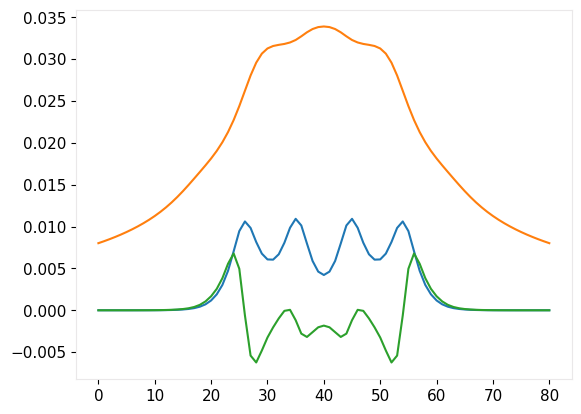

In [32]:
#plt.plot(dens_dir[0].reshape((11,51,11))[5,:,5])
plt.plot(dens_list[30].reshape((51,81,51))[26,:,26]/10)
plt.plot(vks_list[30].reshape((51,81,51))[26,:,26]/40)
plt.plot(dens_dir[29].reshape((51,81,51))[26,:,26])
#plt.plot(-dens_list[0].reshape((11,51,11))[5,:,5]/10)
#plt.plot(-vks_list[0].reshape((11,51,11))[5,:,5]/10)
#plt.plot(-vks_list[1].reshape((11,51,11))[5,:,5]/10)

In [37]:
print(len(vks_list), len(dens_dir))
re_int = [np.dot(dens_dir[i],vks_list[i+1]) for i in range(58)]
#pathint = sum([np.dot(dens_dir[i],vks_list[i+1]) if i not in [0, 16] else np.dot(dens_dir[i],vks_list[i+1])/2 for i in range(17)])*dx*dy*dy/2
#print(ener_list[17]-ener_list[1])
#print(fock_list[:])
#print(tv_list[:])
#print(pathint)
    

60 58


In [38]:
#tv_diff = tv_list[17]-tv_list[1]
#nuc_diff = nuc_list[17]-nuc_list[1]
#tv_diff - nuc_diff+pathint
#print(fock_list[17])

[0.0, -0.07211631843781423, -0.14221526140163604, -0.21001584892338093, -0.27553218418987274, -0.33878589218246047, -0.3996909129231376, -0.45829906105000284, -0.5147906244309847, -0.5692279866590924, -0.6216377355169681, -0.6721749635503514, -0.7209728895089573, -0.7680438800668513, -0.813450030796051, -0.8573293698899754, -0.8997405001373032, -0.9407060753669649, -0.9803393525808304, -1.0187552485204963, -1.0559851228582018, -1.092086643978389, -1.1271719712908772, -1.1612929545202426, -1.194460416359362, -1.2267429251024216, -1.258216562225969, -1.2888999372020649, -1.3188290475202773, -1.3480898230095453, -1.3767483722311642, -1.4048481041144343, -1.4324031349252428, -1.4595082455054365, -1.4862289028019358, -1.512549858240862, -1.5385313057149588, -1.5642168013177953, -1.5896213857263581, -1.6147889610704378, -1.639778789306057, -1.6646177071799455, -1.689327769347656, -1.7139728220962611, -1.7386004651334677, -1.7631996178680194, -1.7877817547553696, -1.8123766358481317, -1.83699

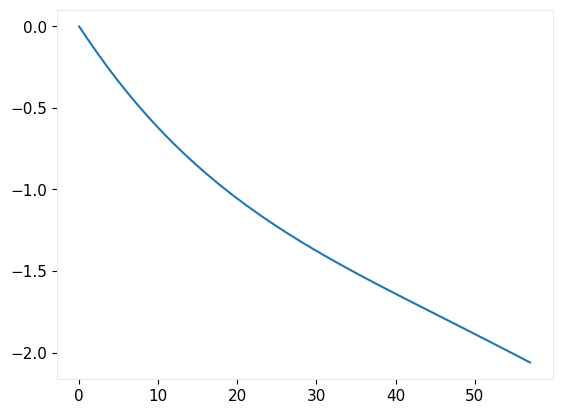

In [39]:
p_int = []
for i in range(0, 58):
    if i == 0:
        p_int.append(0.)
    elif i == 1:
        p_int.append(dx*dy*dy/2*(re_int[0]+re_int[1]))
    else:
        p_int.append(sum([re_int[j]*dx*dy*dy if j not in [0, i] else re_int[j]/2*dx*dy*dy for j in range(i+1)]))
len(p_int)
print(p_int)
plt.plot(p_int)

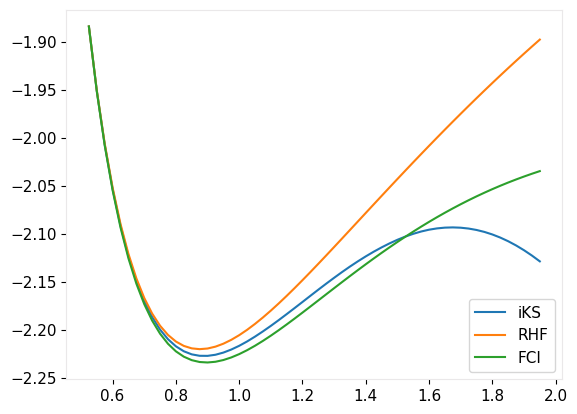

In [42]:
#plt.plot(rs[1:39], tv_list[1:39])
plt.plot(rs[1:59],np.array(tv_list[1:59])+np.array(p_int)+ener_list[1]-tv_list[1]-nuc_list[1]+np.array(nuc_list[1:59]), label="iKS")
plt.plot(rs[1:59], np.array(mf_list[1:59])-mf_list[1]+ener_list[1], label="RHF")
plt.plot(rs[1:59], ener_list[1:59], label="FCI")
plt.legend()